# Section 2 — Threat Landscape: ศัตรูไม่ใช่ก้อนเดียว
**Business Question:** ภัยที่แท้จริงต่อ Shopee คือใคร และต่างกันอย่างไร?

### ข้อมูลที่ใช้ (Verified Public Data)
- **ข้อมูลงบการเงิน DBD (Baseline เปรียบเทียบโครงสร้างรายได้ vs กำไร/ขาดทุน):**
  - **Shopee (ประเทศไทย):** รายได้ 49,965 ล้านบาท | กำไรสุทธิ +4,631 ล้านบาท
  - **Lazada (ประเทศไทย):** รายได้ 28,291 ล้านบาท | กำไรสุทธิ +836 ล้านบาท
  - **TikTok Shop (ประเทศไทย):** รายได้ 12,066 ล้านบาท | **ขาดทุนสุทธิ -3,678 ล้านบาท** (ช่วงทุ่มงบอุดหนุนเพื่อแย่งชิงส่วนแบ่งตลาด)
- **ข้อมูล Temu:** เข้าไทย ก.ค. 2024 มียอดดาวน์โหลดสะสม >10 ล้านครั้ง (AppMagic) แต่ส่วนแบ่ง GMV ยัง <3% เน้นสินค้าราคาถูกส่งตรงจากโรงงานจีน

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import chart_style

chart_style.setup_plot_style()
COLORS = chart_style.COLORS

fin_df = pd.read_csv("../data/processed/sec02_competitor_financials.csv")
threat_df = pd.read_csv("../data/processed/sec02_threat_matrix.csv")
display(fin_df)
display(threat_df)

,platform,revenue_mb,net_profit_mb,gmv_usd_bn,profit_status,model_note
0,Shopee,49965,4631,12.9,Profitable,Strong cash cow + SPX logistics moat
1,TikTok Shop,12066,-3678,7.3,Loss-making,Heavy subsidy & affiliate burn to capture share
2,Lazada,28291,836,5.2,Profitable,Defensive pivot to LazMall & positive EBITDA


,competitor,gmv_threat_score,counter_difficulty_score,quadrant,buying_mode,gmv_share_note
0,TikTok Shop,9.0,8.4,Structural Threat,Impulse / Content-led,48% (Q2 2026)
1,Temu,4.2,6.8,Price Disruptor,Ultra-cheap Factory Direct,<3% (10M+ Downloads)
2,Lazada,5.8,3.5,Traditional Rival,Intent / Brand Mall,7% (Q2 2026)
3,ผู้เล่น Local (NocNoc / Pantip Mall),2.2,2.4,Watchlist,Niche / Vertical Intent,<1%


### กราฟ 2.1 — Revenue vs Profit Scatter
- **สื่ออะไร:** TikTok Shop เติบโตอย่างก้าวกระโดดแต่แลกมาด้วยการเผาเงินขาดทุน (-3,678 ล้านบาท) ขณะที่ Shopee มีฐานกำไรที่แข็งแกร่ง (+4,631 ล้านบาท) ทำให้มี **Financial Runway** ที่เหนือกว่าหากไม่หลงลงไปเล่นสงครามเผาเงินเต็มรูปแบบ

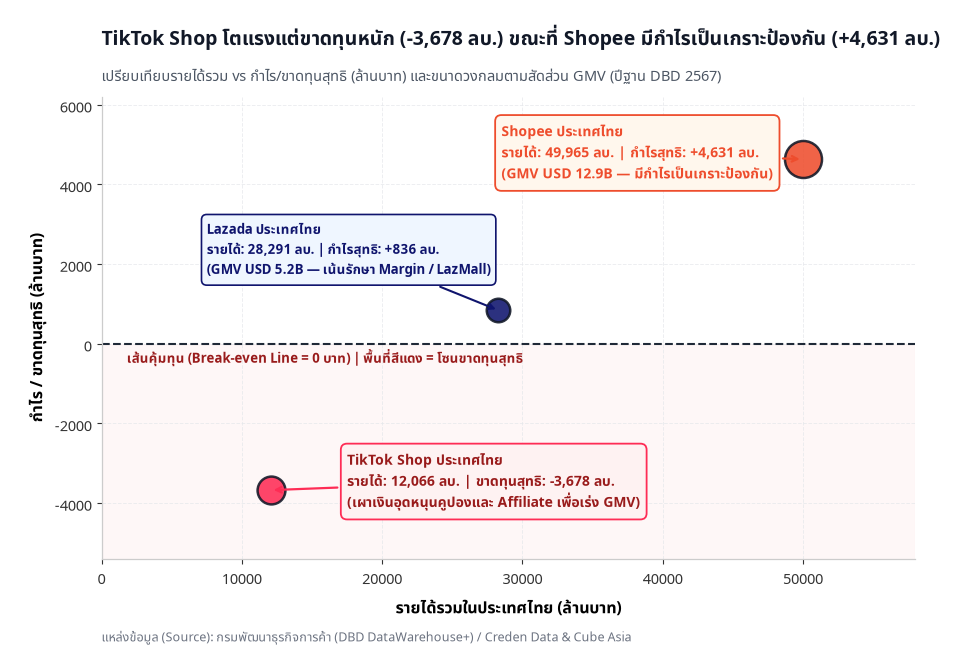

In [2]:
fig, ax = plt.subplots(figsize=(10.5, 6.0))

# Shaded loss zone below zero line
ax.axhspan(-5500, 0, color="#FEF2F2", alpha=0.6, zorder=1)
ax.axhline(0, color="#1F2937", linestyle="--", linewidth=1.5, zorder=2)
ax.text(1800, -480, "เส้นคุ้มทุน (Break-even Line = 0 บาท) | พื้นที่สีแดง = โซนขาดทุนสุทธิ",
        fontsize=9.5, fontweight="bold", color="#991B1B")

for _, row in fin_df.iterrows():
    plat = row["platform"]
    rev = row["revenue_mb"]
    prof = row["net_profit_mb"]
    gmv = row["gmv_usd_bn"]
    color = COLORS["TikTok Red"] if prof < 0 else COLORS.get(plat, COLORS["Grey"])
    size = gmv * 55

    ax.scatter(rev, prof, s=size, color=color, alpha=0.88, edgecolors="#111827", linewidths=1.8, zorder=4)

ax.annotate(
    "Shopee ประเทศไทย\nรายได้: 49,965 ลบ. | กำไรสุทธิ: +4,631 ลบ.\n(GMV USD 12.9B — มีกำไรเป็นเกราะป้องกัน)",
    xy=(49965, 4631), xytext=(28500, 4150),
    fontsize=10, fontweight="bold", color=COLORS["Shopee"],
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#FFF7ED", edgecolor=COLORS["Shopee"], lw=1.3),
    arrowprops=dict(arrowstyle="->", color=COLORS["Shopee"], lw=1.6),
    zorder=5
)

ax.annotate(
    "Lazada ประเทศไทย\nรายได้: 28,291 ลบ. | กำไรสุทธิ: +836 ลบ.\n(GMV USD 5.2B — เน้นรักษา Margin / LazMall)",
    xy=(28291, 836), xytext=(7500, 1750),
    fontsize=9.5, fontweight="bold", color=COLORS["Lazada"],
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#EFF6FF", edgecolor=COLORS["Lazada"], lw=1.2),
    arrowprops=dict(arrowstyle="->", color=COLORS["Lazada"], lw=1.5),
    zorder=5
)

ax.annotate(
    "TikTok Shop ประเทศไทย\nรายได้: 12,066 ลบ. | ขาดทุนสุทธิ: -3,678 ลบ.\n(เผาเงินอุดหนุนคูปองและ Affiliate เพื่อเร่ง GMV)",
    xy=(12066, -3678), xytext=(17500, -4100),
    fontsize=10, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#FEF2F2", edgecolor=COLORS["TikTok Red"], lw=1.3),
    arrowprops=dict(arrowstyle="->", color=COLORS["TikTok Red"], lw=1.6),
    zorder=5
)

ax.set_xlabel("รายได้รวมในประเทศไทย (ล้านบาท)", fontweight="bold")
ax.set_ylabel("กำไร / ขาดทุนสุทธิ (ล้านบาท)", fontweight="bold")
ax.set_xlim(0, 58000)
ax.set_ylim(-5400, 6200)

chart_style.add_title_and_source(
    ax,
    title="TikTok Shop โตแรงแต่ขาดทุนหนัก (-3,678 ลบ.) ขณะที่ Shopee มีกำไรเป็นเกราะป้องกัน (+4,631 ลบ.)",
    subtitle="เปรียบเทียบรายได้รวม vs กำไร/ขาดทุนสุทธิ (ล้านบาท) และขนาดวงกลมตามสัดส่วน GMV (ปีฐาน DBD 2567)",
    source_text="กรมพัฒนาธุรกิจการค้า (DBD DataWarehouse+) / Creden Data & Cube Asia"
)

plt.savefig("../charts/02_1_revenue_vs_profit_scatter.png")
plt.show()

### กราฟ 2.2 — Threat Positioning Matrix (2x2) & เกณฑ์การให้คะแนน (Scoring Rubric)
- **สื่ออะไร:** แยกแยะศัตรูตามระดับภัยคุกคามต่อ GMV และความยากในการตอบโต้ — **TikTok Shop** อยู่ใน Quadrant *"Structural Threat"* (ต้องจัดการเป็นลำดับแรก) ส่วน **Temu** เป็น *"Price Disruptor"* ที่ยังเล็กในแง่ GMV แต่กดดัน Margin ทั้งตลาด

| มิติการประเมิน (Scoring Dimension) | น้ำหนัก (Weight) | TikTok Shop | Temu | Lazada | ผู้เล่น Local |
|---|---|---|---|---|---|
| **1. แกน X: ระดับภัยคุกคามต่อ GMV (GMV Threat Score)** | **100%** | **9.0** | **4.2** | **5.8** | **2.2** |
| - ขนาดส่วนแบ่งตลาดปัจจุบัน (Current GMV Share) | 50% | 9.5 (48% share) | 2.0 (<3% share) | 6.5 (7% share) | 1.5 (<1% share) |
| - อัตราการเติบโตและโมเมนตัม (YoY Growth Velocity) | 30% | 9.5 (+53.4% YoY) | 7.5 (ดาวน์โหลด >10M) | 3.0 (-30.8% YoY) | 3.0 (ทรงตัว) |
| - การทับซ้อนของหมวดสินค้าหลัก (Category Overlap) | 20% | 7.0 (Fashion/Beauty/FMCG) | 4.8 (Non-brand/Long-tail) | 8.2 (Mall/Electronics) | 2.8 (Niche Home/IT) |
| **2. แกน Y: ความยากในการตอบโต้ของ Shopee (Counter Difficulty)** | **100%** | **8.4** | **6.8** | **3.5** | **2.4** |
| - ความแตกต่างของพฤติกรรมผู้ใช้ (Behavioral Shift: Impulse vs Intent) | 45% | 9.2 (Algorithmic Video/Live) | 5.5 (Gamified Factory Direct) | 2.5 (Catalog Search เดียวกัน) | 2.0 (Search ปกติ) |
| - ต้นทุนที่ Shopee ต้องจ่ายหากตอบโต้ตรงๆ (Cost to Match Subsidy) | 35% | 8.5 (ต้องเผางบ Live/Affiliate สูง) | 8.5 (กดราคาแข่งโรงงานจีนไม่ได้) | 4.0 (ใช้ Economy of Scale ชนะได้) | 2.5 (ไม่ต้องใช้งบเพิ่ม) |
| - ความยั่งยืนของสายป่านคู่แข่ง (Parent Backing & Runway) | 20% | 6.5 (ByteDance หนุนเต็มที่) | 6.8 (PDD Supply Chain จีน) | 4.8 (Alibaba เน้นคุมกำไร) | 3.0 (ทุนจำกัด) |

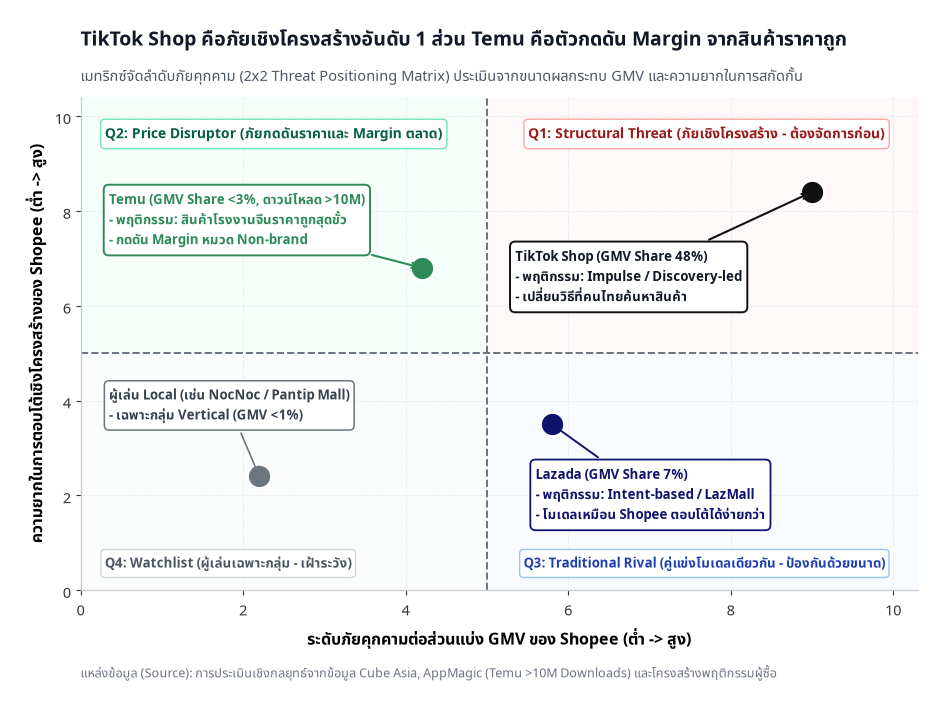

In [3]:
fig, ax = plt.subplots(figsize=(10.8, 6.4))

# Quadrant dividing lines at midpoint 5.0
ax.axvline(5.0, color="#6B7280", linestyle="--", linewidth=1.4, zorder=2)
ax.axhline(5.0, color="#6B7280", linestyle="--", linewidth=1.4, zorder=2)

# Subtle quadrant background shading
ax.fill_between([5.0, 10.5], 5.0, 10.5, color="#FEF2F2", alpha=0.5, zorder=1)
ax.fill_between([0.0, 5.0], 5.0, 10.5, color="#ECFDF5", alpha=0.45, zorder=1)
ax.fill_between([5.0, 10.5], 0.0, 5.0, color="#EFF6FF", alpha=0.4, zorder=1)
ax.fill_between([0.0, 5.0], 0.0, 5.0, color="#F9FAFB", alpha=0.6, zorder=1)

# Quadrant Header Labels placed cleanly at corners
ax.text(9.9, 9.85, "Q1: Structural Threat (ภัยเชิงโครงสร้าง - ต้องจัดการก่อน)",
        ha="right", va="top", fontsize=10, fontweight="bold", color="#991B1B",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFFF", edgecolor="#FCA5A5"))
ax.text(0.3, 9.85, "Q2: Price Disruptor (ภัยกดดันราคาและ Margin ตลาด)",
        ha="left", va="top", fontsize=10, fontweight="bold", color="#065F46",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFFF", edgecolor="#6EE7B7"))
ax.text(9.9, 0.35, "Q3: Traditional Rival (คู่แข่งโมเดลเดียวกัน - ป้องกันด้วยขนาด)",
        ha="right", va="bottom", fontsize=9.5, fontweight="bold", color="#1E40AF",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFFF", edgecolor="#93C5FD"))
ax.text(0.3, 0.35, "Q4: Watchlist (ผู้เล่นเฉพาะกลุ่ม - เฝ้าระวัง)",
        ha="left", va="bottom", fontsize=9.5, fontweight="bold", color="#4B5563",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFFF", edgecolor="#D1D5DB"))

color_map = {
    "TikTok Shop": COLORS["TikTok Shop"],
    "Temu": COLORS["Temu"],
    "Lazada": COLORS["Lazada"],
    "ผู้เล่น Local (NocNoc / Pantip Mall)": COLORS["Local"]
}

for _, row in threat_df.iterrows():
    comp = row["competitor"]
    x_val = row["gmv_threat_score"]
    y_val = row["counter_difficulty_score"]
    c = color_map.get(comp, COLORS["Grey"])

    ax.scatter(x_val, y_val, s=300, color=c, edgecolors="#FFFFFF", linewidths=2.0, zorder=5)

# Non-overlapping callouts inside each quadrant
ax.annotate(
    "TikTok Shop (GMV Share 48%)\n- พฤติกรรม: Impulse / Discovery-led\n- เปลี่ยนวิธีที่คนไทยค้นหาสินค้า",
    xy=(9.0, 8.4), xytext=(5.35, 6.1),
    fontsize=9.5, fontweight="bold", color="#111827",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFFFFF", edgecolor=COLORS["TikTok Shop"], lw=1.4),
    arrowprops=dict(arrowstyle="->", color=COLORS["TikTok Shop"], lw=1.5),
    zorder=6
)

ax.annotate(
    "Temu (GMV Share <3%, ดาวน์โหลด >10M)\n- พฤติกรรม: สินค้าโรงงานจีนราคาถูกสุดขั้ว\n- กดดัน Margin หมวด Non-brand",
    xy=(4.2, 6.8), xytext=(0.35, 7.3),
    fontsize=9.5, fontweight="bold", color=COLORS["Temu"],
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFFFFF", edgecolor=COLORS["Temu"], lw=1.4),
    arrowprops=dict(arrowstyle="->", color=COLORS["Temu"], lw=1.5),
    zorder=6
)

ax.annotate(
    "Lazada (GMV Share 7%)\n- พฤติกรรม: Intent-based / LazMall\n- โมเดลเหมือน Shopee ตอบโต้ได้ง่ายกว่า",
    xy=(5.8, 3.5), xytext=(5.6, 1.5),
    fontsize=9.5, fontweight="bold", color=COLORS["Lazada"],
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFFFFF", edgecolor=COLORS["Lazada"], lw=1.3),
    arrowprops=dict(arrowstyle="->", color=COLORS["Lazada"], lw=1.4),
    zorder=6
)

ax.annotate(
    "ผู้เล่น Local (เช่น NocNoc / Pantip Mall)\n- เฉพาะกลุ่ม Vertical (GMV <1%)",
    xy=(2.2, 2.4), xytext=(0.35, 3.6),
    fontsize=9.5, fontweight="bold", color="#374151",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FFFFFF", edgecolor=COLORS["Local"], lw=1.1),
    arrowprops=dict(arrowstyle="->", color=COLORS["Local"], lw=1.2),
    zorder=6
)

ax.set_xlabel("ระดับภัยคุกคามต่อส่วนแบ่ง GMV ของ Shopee (ต่ำ -> สูง)", fontweight="bold")
ax.set_ylabel("ความยากในการตอบโต้เชิงโครงสร้างของ Shopee (ต่ำ -> สูง)", fontweight="bold")
ax.set_xlim(0, 10.3)
ax.set_ylim(0, 10.4)

chart_style.add_title_and_source(
    ax,
    title="TikTok Shop คือภัยเชิงโครงสร้างอันดับ 1 ส่วน Temu คือตัวกดดัน Margin จากสินค้าราคาถูก",
    subtitle="เมทริกซ์จัดลำดับภัยคุกคาม (2x2 Threat Positioning Matrix) ประเมินจากขนาดผลกระทบ GMV และความยากในการสกัดกั้น",
    source_text="การประเมินเชิงกลยุทธ์จากข้อมูล Cube Asia, AppMagic (Temu >10M Downloads) และโครงสร้างพฤติกรรมผู้ซื้อ"
)

plt.savefig("../charts/02_2_threat_positioning_matrix.png")
plt.show()

> **Insight ของ Section 2:** *"TikTok Shop คือภัยเชิงโครงสร้างที่ต้องจัดลำดับแรก เพราะดึงเวลาและเม็ดเงินผ่าน Impulse Commerce; ส่วน Temu เป็นภัยเชิงราคาที่ยังเล็กในแง่ GMV แต่กดดัน Margin ทั้งตลาด"*